# Tarea 1 – Parte 1: Recolección y limpieza de noticias

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Configuración | Valor |
| :--- | :--- |
| **Opción elegida** | **B – El Comercio** (`elcomercio.pe`) |
| **Fecha de descarga** | se registra automáticamente en la celda siguiente (`FECHA_DESCARGA`) |
| **URL base** | `https://elcomercio.pe` |
| **Fuente de titulares** | Sitemaps de noticias por sección (Google News sitemap), publicados en el `robots.txt` del diario |
| **Fuente de la bajada** | Etiqueta `<meta name="description">` de cada nota (petición HTML individual) |

**URLs base utilizadas:**

- `https://elcomercio.pe/robots.txt`
- `https://elcomercio.pe/sitemap/news/politica/?outputType=xml`
- `https://elcomercio.pe/sitemap/news/economia/?outputType=xml`
- `https://elcomercio.pe/sitemap/news/deporte-total/?outputType=xml`
- `https://elcomercio.pe/sitemap/news/tecnologia/?outputType=xml`

**¿Por qué sitemaps y no la portada HTML?** El `robots.txt` de El Comercio lista explícitamente estos sitemaps
(`Sitemap: https://elcomercio.pe/sitemap/<seccion>/?outputType=xml`), es decir, son el canal que el propio medio
ofrece a los robots. Cada sitemap de noticias trae las últimas 100 notas de la sección con titular, URL y fecha,
lo que alcanza el volumen pedido (~100 por categoría) sin recorrer paginaciones. El RSS oficial
(`/arc/outboundfeeds/rss/category/<seccion>/`) solo devuelve ~18 notas por sección, por eso se descartó como fuente principal.

**Buenas prácticas aplicadas:** se verifica `robots.txt` con `urllib.robotparser` antes de cada URL, `User-Agent`
descriptivo, pausa de 1.5 s entre solicitudes, máximo 1 reintento y caché local en `datos/raw/` para que el notebook
pueda re-ejecutarse sin volver a descargar.

In [1]:
import json
import re
import time
from datetime import datetime
from pathlib import Path
from urllib import robotparser

import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup

# Para que los gráficos Plotly se vean al abrir el notebook en GitHub (imagen estática + HTML interactivo)
pio.renderers.default = "notebook_connected+png"
pio.templates.default = "plotly_white"
ANCHO, ALTO = 950, 480

BASE = "https://elcomercio.pe"
SECCIONES = ["politica", "economia", "deporte-total", "tecnologia"]
USER_AGENT = "Mozilla/5.0 (compatible; TareaDataSciencePUCP/1.0; proyecto academico de clasificacion de titulares)"
PAUSA = 1.5          # segundos entre solicitudes
REINTENTOS = 1       # máximo 1 reintento
RAW = Path("datos/raw")
RAW.mkdir(parents=True, exist_ok=True)

FECHA_DESCARGA = datetime.now().strftime("%Y-%m-%d %H:%M")
print("Medio elegido: Opción B – El Comercio")
print("Fecha de descarga:", FECHA_DESCARGA)

Medio elegido: Opción B – El Comercio
Fecha de descarga: 2026-10-26 00:39


## 1. Revisión de `robots.txt`

In [2]:
sesion = requests.Session()
sesion.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-PE,es;q=0.9"})

robots_txt = sesion.get(f"{BASE}/robots.txt", timeout=30).text
(RAW / "robots_elcomercio.txt").write_text(robots_txt, encoding="utf-8")

rp = robotparser.RobotFileParser()
rp.parse(robots_txt.splitlines())

pruebas = [f"{BASE}/sitemap/news/{s}/?outputType=xml" for s in SECCIONES] + [
    f"{BASE}/politica/ejemplo-noticia/",
    f"{BASE}/buscar/",  # ruta prohibida, como control
]
pd.DataFrame({"url": pruebas, "permitido": [rp.can_fetch(USER_AGENT, u) for u in pruebas]})

,url,permitido
0,https://elcomercio.pe/sitemap/news/politica/?o...,True
1,https://elcomercio.pe/sitemap/news/economia/?o...,True
2,https://elcomercio.pe/sitemap/news/deporte-tot...,True
3,https://elcomercio.pe/sitemap/news/tecnologia/...,True
4,https://elcomercio.pe/politica/ejemplo-noticia/,True
5,https://elcomercio.pe/buscar/,False


Los sitemaps y las notas están permitidos; solo `/buscar/` y `/catalogo/` están prohibidos (no se usan).

In [3]:
ultima_peticion = [0.0]


def descargar(url):
    """GET respetuoso: valida robots.txt, pausa entre solicitudes y un único reintento."""
    if not rp.can_fetch(USER_AGENT, url):
        raise PermissionError(f"robots.txt no permite: {url}")
    for intento in range(REINTENTOS + 1):
        espera = PAUSA - (time.time() - ultima_peticion[0])
        if espera > 0:
            time.sleep(espera)
        try:
            r = sesion.get(url, timeout=30)
            ultima_peticion[0] = time.time()
            if r.status_code == 200:
                return r.text
            print(f"  HTTP {r.status_code} en {url} (intento {intento + 1})")
        except requests.RequestException as e:
            ultima_peticion[0] = time.time()
            print(f"  Error {type(e).__name__} en {url} (intento {intento + 1})")
    return None

## 2. Extracción

### 2.1 Titulares, URL y fecha desde los sitemaps de noticias

Cada XML crudo se guarda en `datos/raw/sitemap_news_<seccion>.xml`. Si el archivo ya existe se reutiliza
(poner `REFRESCAR = True` para forzar una nueva descarga).

In [4]:
REFRESCAR = False

filas = []
for seccion in SECCIONES:
    archivo = RAW / f"sitemap_news_{seccion}.xml"
    if REFRESCAR or not archivo.exists():
        xml = descargar(f"{BASE}/sitemap/news/{seccion}/?outputType=xml")
        archivo.write_text(xml, encoding="utf-8")
    sopa = BeautifulSoup(archivo.read_text(encoding="utf-8"), "xml")
    for nodo in sopa.find_all("url"):
        filas.append({
            "titular": nodo.find("news:title").get_text(strip=True) if nodo.find("news:title") else "",
            "url": nodo.find("loc").get_text(strip=True),
            "fecha": nodo.find("news:publication_date").get_text(strip=True)[:10] if nodo.find("news:publication_date") else "",
            "sitemap": seccion,
        })

crudo = pd.DataFrame(filas)
print("Filas crudas:", crudo.shape)
crudo.groupby("sitemap").size()

Filas crudas: (400, 4)


sitemap
deporte-total    100
economia         100
politica         100
tecnologia       100
dtype: int64

### 2.2 Sección original (desde la ruta de la URL)

La URL de El Comercio tiene la forma `https://elcomercio.pe/<seccion>/<subseccion>/<slug>/`. Se toma
`<seccion>/<subseccion>` como `seccion_original` (por ejemplo `deporte-total/futbol-peruano`); si la nota cuelga
directamente de la sección, se usa solo `<seccion>`.

In [5]:
def seccion_desde_url(url):
    partes = [p for p in url.replace(BASE, "").split("/") if p]
    if len(partes) >= 3:
        return f"{partes[0]}/{partes[1]}"
    return partes[0]


crudo["seccion_original"] = crudo["url"].map(seccion_desde_url)
crudo["medio"] = "El Comercio"
crudo["seccion_original"].value_counts().head(15)

seccion_original
economia/peru                         51
deporte-total/futbol-peruano          37
tecnologia/actualidad                 34
politica/congreso                     31
politica                              26
deporte-total/futbol-mundial          24
tecnologia/inteligencia-artificial    21
politica/gobierno                     17
economia/mercados                     16
economia                              14
opinion/columnistas                   10
tecnologia/ciencias                   10
politica/actualidad                    9
deporte-total/espana                   9
tecnologia/ecologia                    9
Name: count, dtype: int64

### 2.3 Bajada desde cada nota

La bajada (subtítulo) de El Comercio se publica en `<meta name="description">` de cada nota. Se hace una
petición por URL única (≈400 × 1.5 s ≈ 10 min la primera vez). Los resultados se van guardando línea por línea en
`datos/raw/bajadas.jsonl`, así que si el proceso se interrumpe se retoma donde quedó.

In [6]:
archivo_bajadas = RAW / "bajadas.jsonl"
bajadas = {}
if archivo_bajadas.exists():
    for linea in archivo_bajadas.read_text(encoding="utf-8").splitlines():
        reg = json.loads(linea)
        bajadas[reg["url"]] = reg

pendientes = [u for u in crudo["url"].drop_duplicates() if u not in bajadas]
print(f"En caché: {len(bajadas)} | Pendientes: {len(pendientes)}")


def extraer_bajada(html):
    sopa = BeautifulSoup(html, "lxml")
    for atributos in ({"name": "description"}, {"property": "og:description"}):
        meta = sopa.find("meta", attrs=atributos)
        if meta and meta.get("content", "").strip():
            return meta["content"].strip()
    return ""


with archivo_bajadas.open("a", encoding="utf-8") as f:
    for i, url in enumerate(pendientes, 1):
        html = descargar(url)
        reg = {"url": url, "bajada": extraer_bajada(html) if html else "", "ok": html is not None}
        bajadas[url] = reg
        f.write(json.dumps(reg, ensure_ascii=False) + "\n")
        if i % 50 == 0:
            print(f"  {i}/{len(pendientes)} notas descargadas")

crudo["bajada"] = crudo["url"].map(lambda u: bajadas.get(u, {}).get("bajada", ""))
crudo.to_csv(RAW / "noticias_crudo.csv", index=False)
print("Notas con bajada:", (crudo["bajada"].str.len() > 0).sum(), "de", len(crudo))
crudo.head()

En caché: 399 | Pendientes: 0
Notas con bajada: 400 de 400


,titular,url,fecha,sitemap,seccion_original,medio,bajada
0,Luis Galarreta sobre delegación de facultades:...,https://elcomercio.pe/politica/gobierno/luis-g...,2026-10-25,politica,politica/gobierno,El Comercio,"El jefe del Gabinete Ministerial, Luis Galarre..."
1,Caso Ascensos: Revelan que denuncia constituci...,https://elcomercio.pe/politica/congreso/pedro-...,2026-10-25,politica,politica/congreso,El Comercio,La denuncia constitucional contra el golpista ...
2,Keiko Fujimori recibe facultades: ¿Cuáles será...,https://elcomercio.pe/politica/keiko-fujimori-...,2026-10-25,politica,politica,El Comercio,El gobierno de Keiko Fujimori obtuvo una parte...
3,Keiko Fujimori felicita a Lula da Silva tras g...,https://elcomercio.pe/politica/gobierno/keiko-...,2026-10-25,politica,politica/gobierno,El Comercio,La presidenta Keiko Fujimori felicitó a su hom...
4,"Manos a Obras, una crónica de Fernando Vivas s...",https://elcomercio.pe/politica/manos-a-obras-u...,2026-10-25,politica,politica,El Comercio,"Gracias al Partido Cívico Obras, el Ejecutivo ..."


## 3. Limpieza y normalización

In [7]:
def limpiar_texto(t):
    """Normaliza espacios y saltos de línea; no altera el contenido del titular."""
    return re.sub(r"\s+", " ", str(t)).strip()


df = crudo.copy()
df["titular"] = df["titular"].fillna("").map(limpiar_texto)
df["bajada"] = df["bajada"].fillna("").map(limpiar_texto)

descartes = []

# a) titulares vacíos
vacios = df["titular"].str.len() == 0
descartes.append(("Titular vacío", int(vacios.sum())))
df = df[~vacios]

# b) duplicados por URL (una nota puede aparecer en más de un sitemap)
dup_url = df.duplicated("url", keep="first")
descartes.append(("URL duplicada", int(dup_url.sum())))
df = df[~dup_url]

# c) duplicados por titular (misma nota publicada con dos URLs distintas)
dup_tit = df["titular"].str.lower().duplicated(keep="first")
descartes.append(("Titular duplicado (URL distinta)", int(dup_tit.sum())))
df = df[~dup_tit]

print("Filas tras limpieza de vacíos/duplicados:", len(df))

Filas tras limpieza de vacíos/duplicados: 399


### 3.1 Tabla de equivalencias `seccion_original` → `etiqueta`

El mapeo se hace sobre la sección principal de la URL (primer segmento). Cualquier sección que no esté en la tabla
se descarta y se reporta (no se crea una quinta categoría).

In [8]:
MAPEO_SECCION = {
    "politica": "politica",
    "economia": "economia",
    "deporte-total": "deportes",
    "tecnologia": "ciencia_tecnologia",
}

df["seccion_principal"] = df["seccion_original"].str.split("/").str[0]
df["etiqueta"] = df["seccion_principal"].map(MAPEO_SECCION)

tabla_mapeo = (
    df.groupby(["seccion_original", "etiqueta"], dropna=False)
    .size()
    .reset_index(name="n_noticias")
    .sort_values(["etiqueta", "n_noticias"], ascending=[True, False])
)
tabla_mapeo

,seccion_original,etiqueta,n_noticias
31,tecnologia/actualidad,ciencia_tecnologia,34
36,tecnologia/inteligencia-artificial,ciencia_tecnologia,21
33,tecnologia/ciencias,ciencia_tecnologia,10
34,tecnologia/ecologia,ciencia_tecnologia,9
32,tecnologia/ciberseguridad,ciencia_tecnologia,6
41,tecnologia/videojuegos,ciencia_tecnologia,5
37,tecnologia/moviles,ciencia_tecnologia,4
35,tecnologia/gadgets,ciencia_tecnologia,3
38,tecnologia/redes-sociales,ciencia_tecnologia,2
39,tecnologia/robotica,ciencia_tecnologia,1


In [9]:
sin_categoria = df["etiqueta"].isna()
if sin_categoria.any():
    print("Secciones sin equivalencia (descartadas):")
    print(df.loc[sin_categoria, "seccion_original"].value_counts())
descartes.append(("Sección fuera de las 4 categorías", int(sin_categoria.sum())))
df = df[~sin_categoria]

# d) notas cuya descarga HTML falló: se conservan (el titular es válido), con bajada vacía
sin_bajada = int((df["bajada"].str.len() == 0).sum())

reporte_descartes = pd.DataFrame(descartes, columns=["motivo", "n_descartadas"])
reporte_descartes.loc[len(reporte_descartes)] = ["TOTAL descartadas", reporte_descartes["n_descartadas"].sum()]
print(f"Filas crudas: {len(crudo)} → filas finales: {len(df)}")
print(f"Notas conservadas sin bajada (no se pudo leer la meta descripción): {sin_bajada}")
reporte_descartes

Secciones sin equivalencia (descartadas):
seccion_original
opinion/columnistas          10
ecdata                        2
lima/sucesos                  1
ruedas-tuercas/automotriz     1
bbc-news-mundo                1
eldominical/ciencia           1
Name: count, dtype: int64
Filas crudas: 400 → filas finales: 383
Notas conservadas sin bajada (no se pudo leer la meta descripción): 0


,motivo,n_descartadas
0,Titular vacío,0
1,URL duplicada,1
2,Titular duplicado (URL distinta),0
3,Sección fuera de las 4 categorías,16
4,TOTAL descartadas,17


## 4. Análisis exploratorio (EDA)

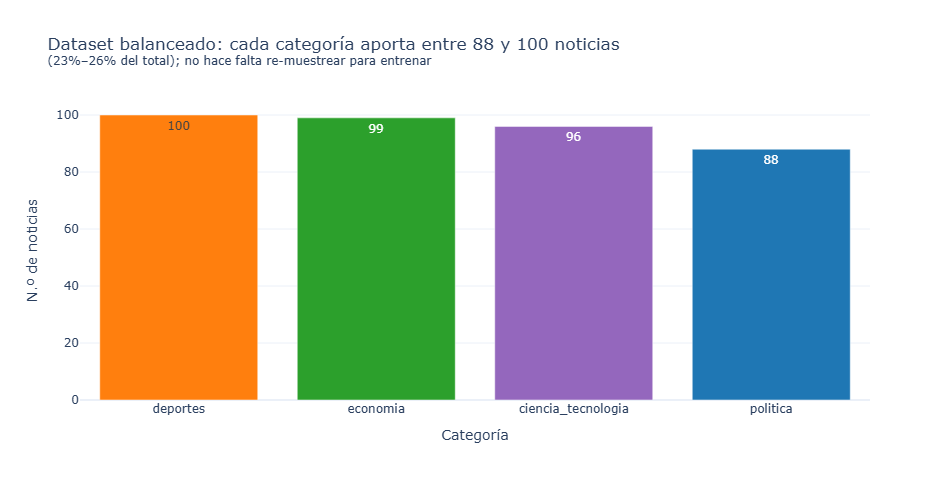

In [10]:
COLORES = {"politica": "#1f77b4", "economia": "#2ca02c", "deportes": "#ff7f0e", "ciencia_tecnologia": "#9467bd"}

conteo = df["etiqueta"].value_counts().reset_index()
conteo.columns = ["etiqueta", "n"]
fig = px.bar(
    conteo, x="etiqueta", y="n", color="etiqueta", text="n", color_discrete_map=COLORES,
    title=f"Dataset balanceado: cada categoría aporta entre {conteo.n.min()} y {conteo.n.max()} noticias<br>"
          f"<sup>({conteo.n.min() / conteo.n.sum():.0%}–{conteo.n.max() / conteo.n.sum():.0%} del total); "
          f"no hace falta re-muestrear para entrenar</sup>",
    labels={"etiqueta": "Categoría", "n": "N.º de noticias"},
)
fig.update_layout(showlegend=False, width=ANCHO, height=ALTO)
fig.show()

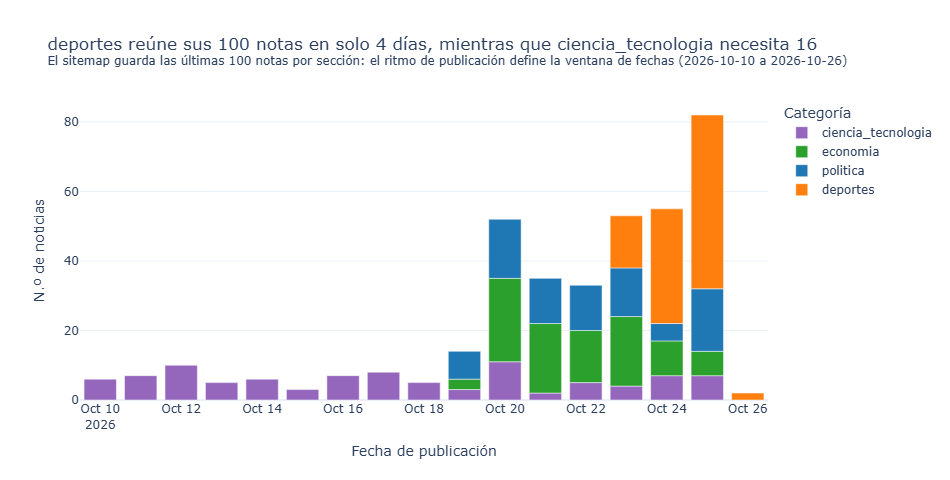

etiqueta
deportes               4
economia               7
politica               7
ciencia_tecnologia    16
Name: días con publicaciones, dtype: int64

In [11]:
df["fecha"] = pd.to_datetime(df["fecha"])
por_dia = df.groupby([df["fecha"].dt.date, "etiqueta"]).size().reset_index(name="n")
por_dia.columns = ["fecha", "etiqueta", "n"]
dias = df["fecha"].dt.date
cobertura = df.groupby("etiqueta")["fecha"].agg(lambda f: f.dt.date.nunique()).sort_values()
fig = px.bar(
    por_dia, x="fecha", y="n", color="etiqueta", color_discrete_map=COLORES,
    title=f"{cobertura.index[0]} reúne sus {(df.etiqueta == cobertura.index[0]).sum()} notas en solo {cobertura.iloc[0]} días, "
          f"mientras que {cobertura.index[-1]} necesita {cobertura.iloc[-1]}<br>"
          f"<sup>El sitemap guarda las últimas 100 notas por sección: el ritmo de publicación define la ventana de fechas "
          f"({dias.min()} a {dias.max()})</sup>",
    labels={"fecha": "Fecha de publicación", "n": "N.º de noticias", "etiqueta": "Categoría"},
)
fig.update_layout(width=ANCHO, height=ALTO)
fig.show()
cobertura.rename("días con publicaciones")

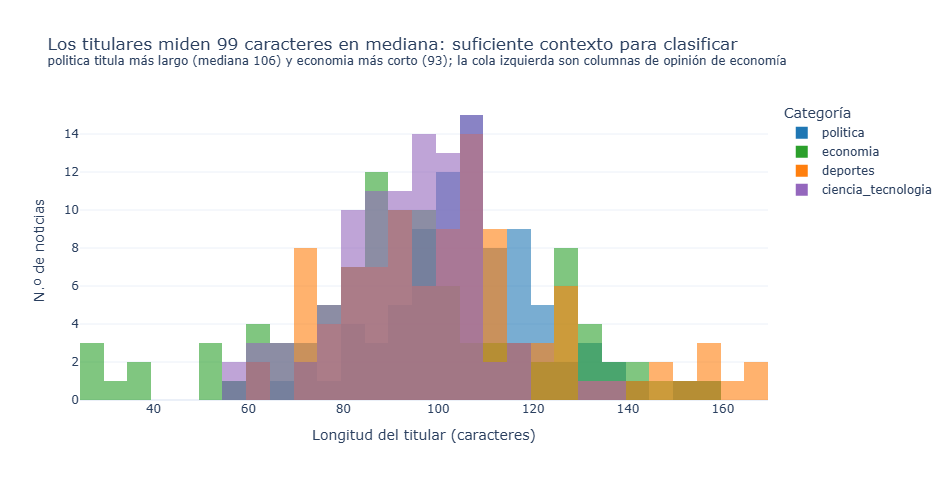

,count,mean,std,min,25%,50%,75%,max
etiqueta,,,,,,,,
ciencia_tecnologia,96.0,93.0,14.7,59.0,84.0,95.0,103.0,138.0
deportes,100.0,104.6,23.6,62.0,87.8,103.5,114.0,167.0
economia,99.0,94.0,28.2,25.0,81.0,93.0,111.0,155.0
politica,88.0,104.7,18.8,58.0,96.0,106.0,115.0,157.0


In [12]:
df["largo_titular"] = df["titular"].str.len()
medianas = df.groupby("etiqueta")["largo_titular"].median().sort_values()
fig = px.histogram(
    df, x="largo_titular", color="etiqueta", nbins=30, barmode="overlay", opacity=0.6,
    color_discrete_map=COLORES,
    title=f"Los titulares miden {df.largo_titular.median():.0f} caracteres en mediana: suficiente contexto para clasificar<br>"
          f"<sup>{medianas.index[-1]} titula más largo (mediana {medianas.iloc[-1]:.0f}) y {medianas.index[0]} más corto "
          f"({medianas.iloc[0]:.0f}); la cola izquierda son columnas de opinión de economía</sup>",
    labels={"largo_titular": "Longitud del titular (caracteres)", "etiqueta": "Categoría"},
)
fig.update_layout(width=ANCHO, height=ALTO, yaxis_title="N.º de noticias")
fig.show()
df.groupby("etiqueta")["largo_titular"].describe().round(1)

## 5. Validación: titulares más largos y más cortos

In [13]:
pd.set_option("display.max_colwidth", 140)
print("5 titulares MÁS LARGOS")
display(df.nlargest(5, "largo_titular")[["largo_titular", "etiqueta", "titular"]])
print("5 titulares MÁS CORTOS")
display(df.nsmallest(5, "largo_titular")[["largo_titular", "etiqueta", "titular"]])

5 titulares MÁS LARGOS


,largo_titular,etiqueta,titular
265,167,deportes,"“Tiene habilidad, falta musculatura” y “Aún es parte del universo de convocables”: cinco voces autorizadas sobre el futuro de Maxloren C..."
211,165,deportes,"“Para una hipotética final Alianza pediría árbitro y VAR extranjeros, además de goal line”: Alfredo Arosemena y su postura sobre el arbi..."
201,160,deportes,El “Quedan 4 finales” de Guede y el cántico de 5 mil hinchas que coparon Moquegua: lo que no se vio del dramático 1-0 que mantiene vivo ...
269,159,deportes,"“Campeoné y me mandaron a la asistenta social para renovar por 60% menos de mi sueldo y meter a Ahmed”: J.J. Oré, el último técnico exit..."
251,158,deportes,“El culpable soy yo” de Mosquera y por qué sacó a Yotún con el 2-0 en contra: lo que no se vio del tropezón de Cristal en Cusco que lo d...


5 titulares MÁS CORTOS


,largo_titular,etiqueta,titular
196,25,economia,Minería multigeneracional
171,27,economia,Las muchas caras de El Niño
106,28,economia,¿De qué se compone un motín?
134,32,economia,El Niño: más allá de las lluvias
151,36,economia,Inclusión al otro lado del mostrador


Los extremos coinciden con las colas del histograma:

- **Más largos (~160 caracteres):** todos son de *deportes* y combinan una cita textual entre comillas con una
  explicación ("lo que no se vio del…"). Es el estilo de crónica deportiva de El Comercio, de ahí la cola derecha naranja.
- **Más cortos (25–36 caracteres):** son de *economía* y corresponden a columnas de opinión (por ejemplo
  "Minería multigeneracional"), titulares-concepto sin verbo. Explican las barras verdes aisladas a la izquierda.

Ningún extremo es un error de extracción (no hay HTML residual, textos cortados ni vacíos). Los titulares
cortos de opinión serán los más difíciles para el clasificador porque casi no contienen palabras clave.

## 6. Exportación de `datos/noticias.csv`

In [14]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
final = df[COLUMNAS].copy()
final["fecha"] = final["fecha"].dt.strftime("%Y-%m-%d")
final = final.reset_index(drop=True)
final.to_csv("datos/noticias.csv", index=False, encoding="utf-8")

print("df.shape:", final.shape)
final.head()

df.shape: (383, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Luis Galarreta sobre delegación de facultades: “Vamos a hacer un uso efectivo y contundente de lo que nos han dado”,"El jefe del Gabinete Ministerial, Luis Galarreta, afirmó que el Poder Ejecutivo hará un “uso efectivo y contundente” de la delegación de...",El Comercio,politica/gobierno,https://elcomercio.pe/politica/gobierno/luis-galarreta-sobre-delegacion-de-facultades-vamos-a-hacer-un-uso-efectivo-y-contundente-de-lo-...,2026-10-25,politica
1,Caso Ascensos: Revelan que denuncia constitucional contra Pedro Castillo por presuntas coimas está en riesgo de caducar,"La denuncia constitucional contra el golpista expresidente Pedro Castillo (2021-2022) por presuntas coimas en el Caso Ascensos, que está...",El Comercio,politica/congreso,https://elcomercio.pe/politica/congreso/pedro-castillo-revelan-que-denuncia-constitucional-contra-expresidente-por-presuntas-coimas-por-...,2026-10-25,politica
2,Keiko Fujimori recibe facultades: ¿Cuáles serán los primeros decretos legislativos que se dictarán?,El gobierno de Keiko Fujimori obtuvo una parte de las facultades para legislar que solicitó al Congreso hace casi dos meses. El Senado a...,El Comercio,politica,https://elcomercio.pe/politica/keiko-fujimori-recibe-facultades-cuales-seran-los-primeros-decretos-legislativos-que-se-daran-apuesplan-n...,2026-10-25,politica
3,Keiko Fujimori felicita a Lula da Silva tras ganar la segunda vuelta en las elecciones en Brasil,"La presidenta Keiko Fujimori felicitó a su homólogo de Brasil, Lula da Silva, por su reelección, tras ganar la segunda vuelta en las ele...",El Comercio,politica/gobierno,https://elcomercio.pe/politica/gobierno/keiko-fujimori-felicita-a-lula-da-silva-tras-ganar-la-segunda-vuelta-en-las-elecciones-en-brasil...,2026-10-25,politica
4,"Manos a Obras, una crónica de Fernando Vivas sobres las facultades para el Ejecutivo","Gracias al Partido Cívico Obras, el Ejecutivo superó la crisis de las facultades. Si sus coincidencias se prolongaran, cambiaría, inclus...",El Comercio,politica,https://elcomercio.pe/politica/manos-a-obras-una-cronica-de-fernando-vivas-sobres-las-facultades-para-el-ejecutivo-apuesplan-noticia/,2026-10-25,politica


In [15]:
# Verificación rápida de que las URLs funcionan: 10 URLs al azar (con la misma pausa respetuosa)
muestra = final.sample(10, random_state=42)["url"]
estado = []
for u in muestra:
    espera = PAUSA - (time.time() - ultima_peticion[0])
    if espera > 0:
        time.sleep(espera)
    r = sesion.head(u, timeout=30, allow_redirects=True)
    ultima_peticion[0] = time.time()
    estado.append(r.status_code)
pd.DataFrame({"url": muestra.values, "http_status": estado})

,url,http_status
0,https://elcomercio.pe/deporte-total/futbol-mundial/voy-a-pasar-un-ano-sin-hacer-nada-la-frase-viral-de-neymar-sobre-sus-planes-cuando-se...,200
1,https://elcomercio.pe/deporte-total/polideportivo/paramount-plus-en-vivo-online-donde-ver-volkanovski-vs-evloev-hoy-gratis-en-ufc-333-no...,200
2,https://elcomercio.pe/tecnologia/ciencias/como-es-la-revolucionaria-mision-que-busca-traer-un-trozo-de-la-mayor-luna-de-marte-a-la-tierr...,200
3,https://elcomercio.pe/tecnologia/ciberseguridad/estafas-digitales-contra-adultos-mayores-seis-recomendaciones-para-proteger-a-padres-y-a...,200
4,https://elcomercio.pe/politica/congreso/votos-de-dos-senadores-de-buen-gobierno-a-favor-de-delegacion-de-facultades-se-vera-en-la-intern...,200
5,https://elcomercio.pe/tecnologia/actualidad/por-que-deberias-mantener-apagado-el-bluetooth-de-tu-celular-cuando-no-lo-usas-noticia-2/,200
6,https://elcomercio.pe/politica/congreso/senadores-de-juntos-por-el-peru-presentaran-demanda-de-inconstitucionalidad-por-aprobacion-de-fa...,200
7,https://elcomercio.pe/economia/peru/fitch-ratings-mantiene-la-calificacion-soberana-de-peru-en-bbb-con-perspectiva-estable-l-ultimas-not...,200
8,https://elcomercio.pe/tecnologia/actualidad/ben-affleck-se-revela-como-un-entusiasta-y-experto-en-inteligencia-artificial-superinteligen...,200
9,https://elcomercio.pe/deporte-total/futbol-peruano/sporting-cristal-el-culpable-soy-yo-de-roberto-mosquera-y-por-que-saco-a-yotun-con-el...,200
